# Exploratory Data Analysis (EDA) Project
**Task 3 – Uncovering patterns, correlations and key influencing factors**

**Dataset:** Wine recognition dataset (UCI / scikit-learn). 178 wines from 3 grape cultivars in the same Italian region, each described by 13 chemical measurements.

**Question we explore:** *Which chemical properties differ most between the three cultivars, and how do the properties relate to each other?*

**Structure of this report**
1. Data overview and quality check
2. Statistical summary
3. Distributions
4. Relationships and correlations
5. Key influencing factors (what separates the cultivars)
6. Insights and conclusion

## 1. Data overview and quality check

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.feature_selection import f_classif

sns.set_theme(style="whitegrid", context="notebook")

wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["cultivar"] = df["target"].map({0: "Class 0", 1: "Class 1", 2: "Class 2"})
features = list(wine.feature_names)

print("Rows, columns:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print()
print(df["cultivar"].value_counts().sort_index())
df.head()

Rows, columns: (178, 15)
Missing values: 0
Duplicate rows: 0

cultivar
Class 0    59
Class 1    71
Class 2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,Class 0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,Class 0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,Class 0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,Class 0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,Class 0


The data is clean: no missing values and no duplicates. The three classes are reasonably balanced, so no class dominates the analysis.

## 2. Statistical summary

In [2]:
summary = df[features].describe().T[["mean", "std", "min", "50%", "max"]].round(2)
summary["skew"] = df[features].skew().round(2)
summary

,mean,std,min,50%,max,skew
alcohol,13.00,0.81,11.03,13.05,14.83,-0.05
malic_acid,2.34,1.12,0.74,1.87,5.80,1.04
ash,2.37,0.27,1.36,2.36,3.23,-0.18
alcalinity_of_ash,19.49,3.34,10.60,19.50,30.00,0.21
magnesium,99.74,14.28,70.00,98.00,162.00,1.10
total_phenols,2.30,0.63,0.98,2.36,3.88,0.09
flavanoids,2.03,1.00,0.34,2.13,5.08,0.03
nonflavanoid_phenols,0.36,0.12,0.13,0.34,0.66,0.45
proanthocyanins,1.59,0.57,0.41,1.56,3.58,0.52
color_intensity,5.06,2.32,1.28,4.69,13.00,0.87


Features are on very different scales (proline is in the hundreds to 1000s, hue is around 1). That is why we compare features using correlations and standardised statistics rather than raw values.

## 3. Distributions

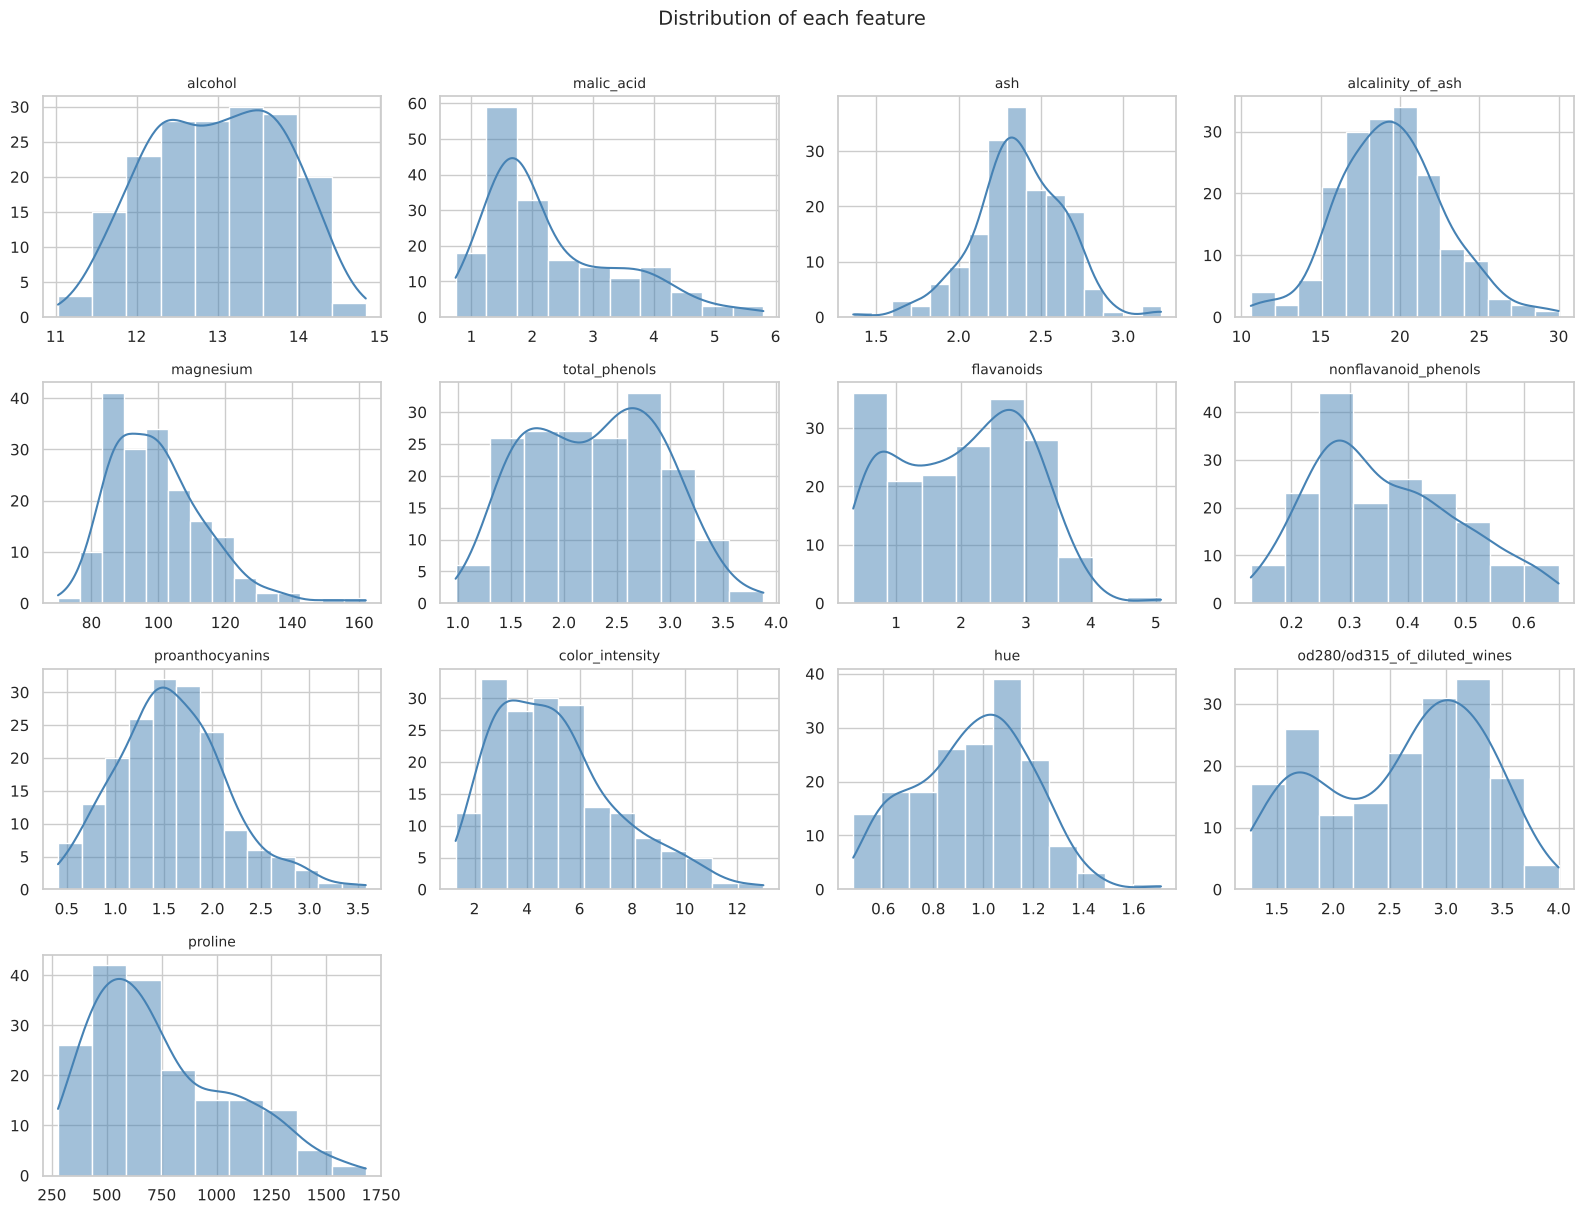

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
plt.suptitle("Distribution of each feature", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig("distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Outliers (box plots, standardised so all features share one axis)

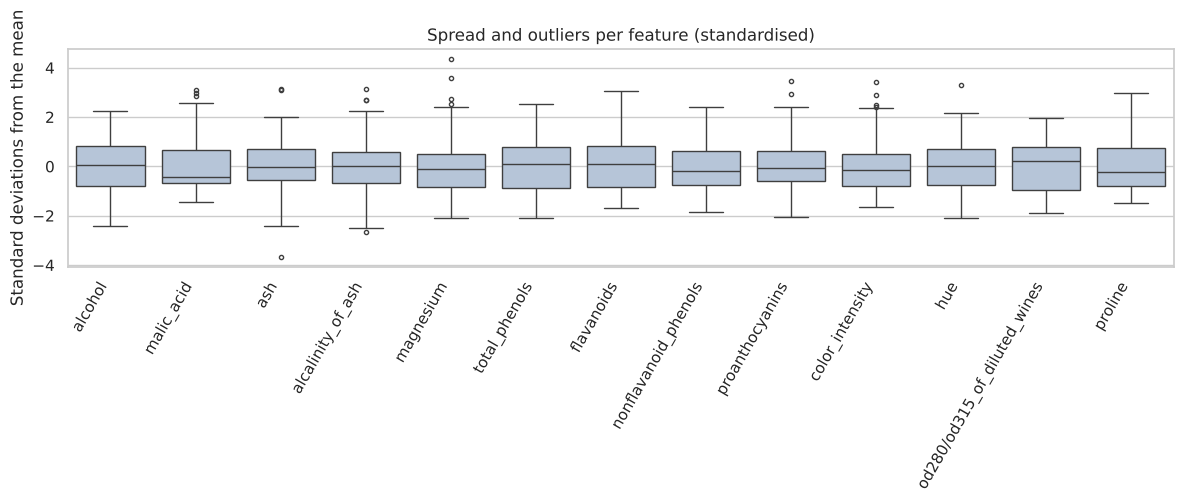

Values more than 3 SD from the mean:
malic_acid           1
ash                  3
alcalinity_of_ash    1
magnesium            2
flavanoids           1
proanthocyanins      1
color_intensity      1
hue                  1
dtype: int64


In [4]:
z = (df[features] - df[features].mean()) / df[features].std()
plt.figure(figsize=(12, 5))
sns.boxplot(data=z, orient="v", color="lightsteelblue", fliersize=3)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Standard deviations from the mean")
plt.title("Spread and outliers per feature (standardised)")
plt.tight_layout()
plt.savefig("outliers_boxplot.png", dpi=150)
plt.show()

outlier_counts = (z.abs() > 3).sum()
print("Values more than 3 SD from the mean:")
print(outlier_counts[outlier_counts > 0])

## 4. Relationships and correlations

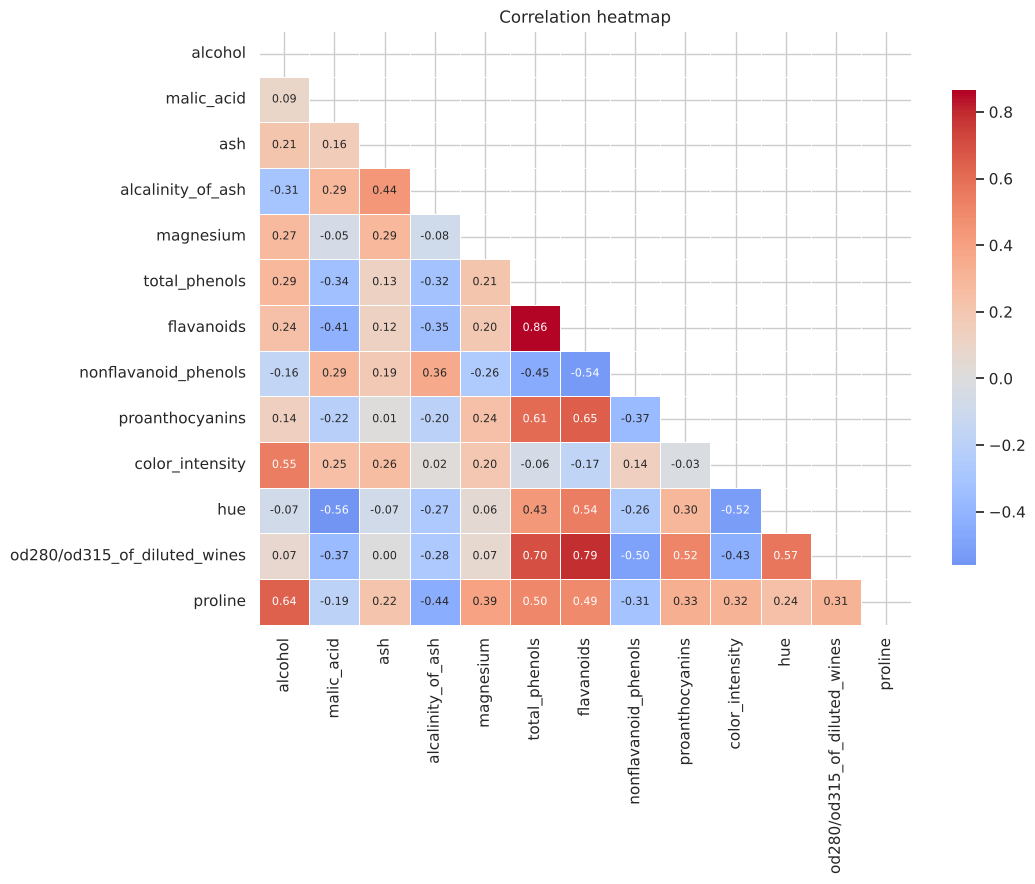

In [5]:
corr = df[features].corr()
plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

In [6]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs.dropna().rename("correlation").sort_values()
print("Strongest NEGATIVE correlations:")
print(pairs.head(5).round(2).to_string())
print()
print("Strongest POSITIVE correlations:")
print(pairs.tail(5).iloc[::-1].round(2).to_string())

Strongest NEGATIVE correlations:
malic_acid            hue                            -0.56
flavanoids            nonflavanoid_phenols           -0.54
color_intensity       hue                            -0.52
nonflavanoid_phenols  od280/od315_of_diluted_wines   -0.50
total_phenols         nonflavanoid_phenols           -0.45

Strongest POSITIVE correlations:
total_phenols  flavanoids                      0.86
flavanoids     od280/od315_of_diluted_wines    0.79
total_phenols  od280/od315_of_diluted_wines    0.70
flavanoids     proanthocyanins                 0.65
alcohol        proline                         0.64


### Pairplot of the most informative features, coloured by cultivar

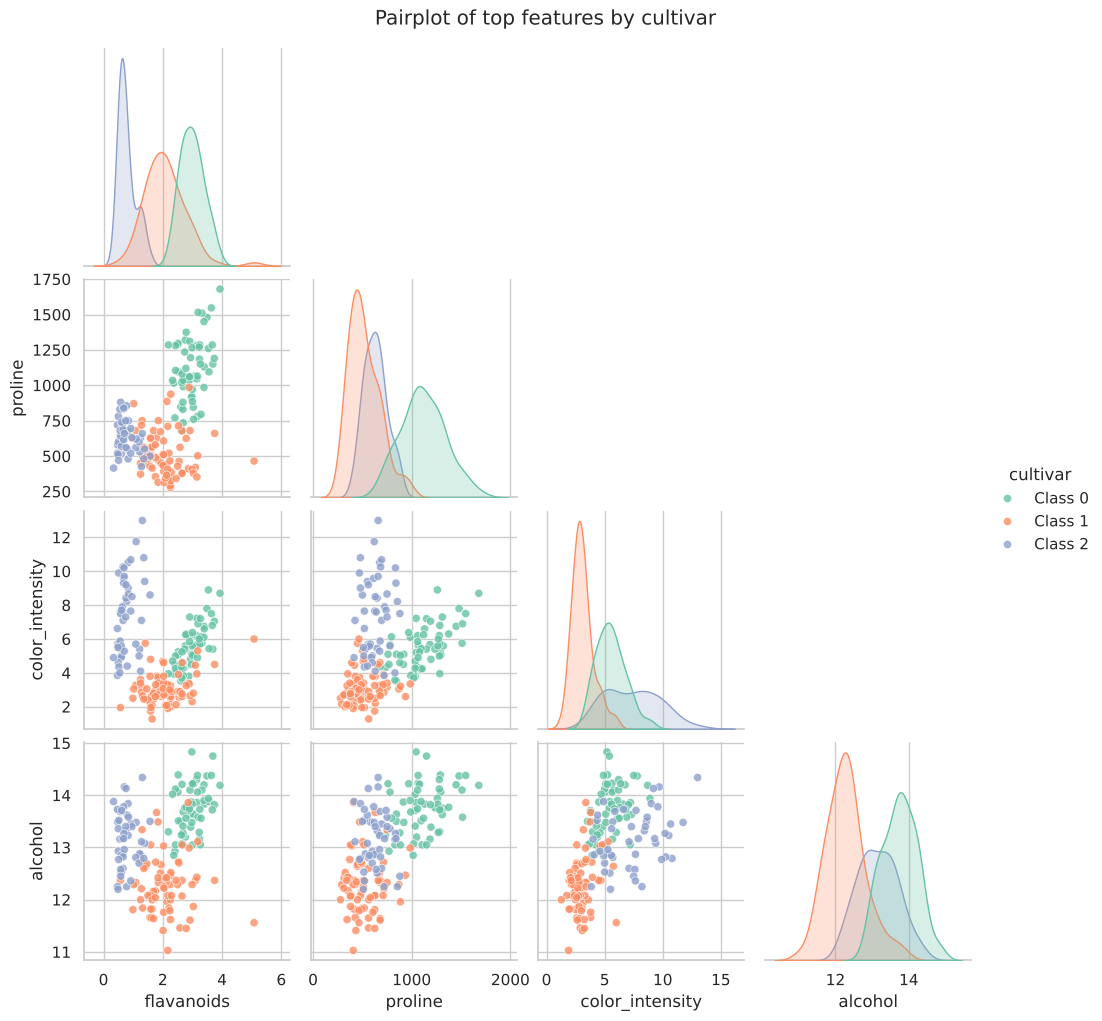

In [7]:
top = ["flavanoids", "proline", "color_intensity", "alcohol"]
g = sns.pairplot(df, vars=top, hue="cultivar", palette="Set2", corner=True,
                 plot_kws={"alpha": 0.8, "s": 35})
g.figure.suptitle("Pairplot of top features by cultivar", y=1.02)
g.savefig("pairplot.png", dpi=150)
plt.show()

## 5. Key influencing factors: what separates the cultivars?

                              F-score       p-value
flavanoids                      233.9  3.598586e-50
proline                         207.9  5.783168e-47
od280/od315_of_diluted_wines    190.0  1.393105e-44
alcohol                         135.1  3.319504e-36
color_intensity                 120.7  1.162008e-33
hue                             101.3  5.917662e-30
total_phenols                    93.7  2.137670e-28
malic_acid                       36.9  4.127229e-14


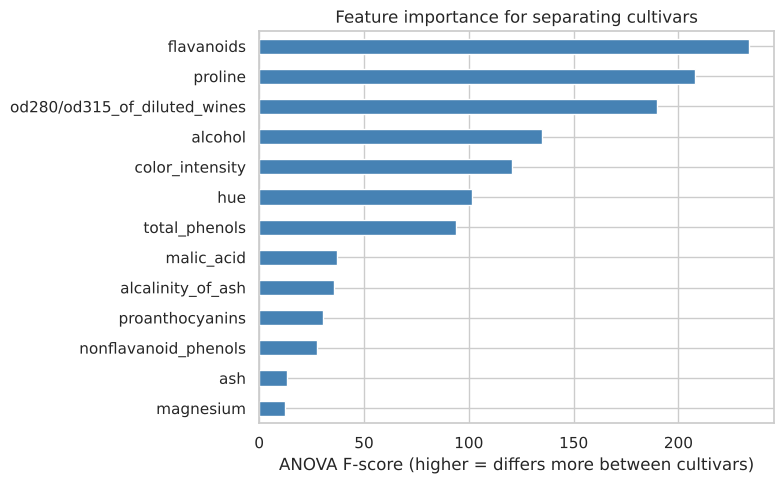

In [8]:
F, p = f_classif(df[features], df["target"])
anova = pd.DataFrame({"F-score": F, "p-value": p}, index=features).sort_values("F-score", ascending=False)
anova["F-score"] = anova["F-score"].round(1)
print(anova.head(8))

plt.figure(figsize=(8, 5))
anova["F-score"].iloc[::-1].plot(kind="barh", color="steelblue")
plt.xlabel("ANOVA F-score (higher = differs more between cultivars)")
plt.title("Feature importance for separating cultivars")
plt.tight_layout()
plt.savefig("key_factors.png", dpi=150)
plt.show()

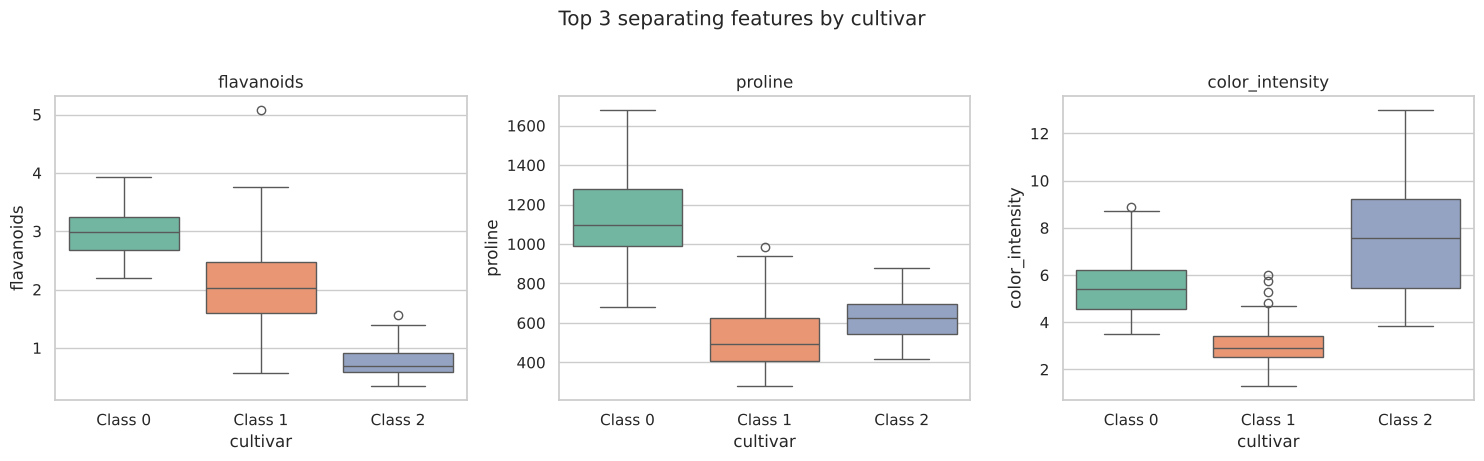

,flavanoids,proline,color_intensity,alcohol,hue
cultivar,,,,,
Class 0,2.98,1115.71,5.53,13.74,1.06
Class 1,2.08,519.51,3.09,12.28,1.06
Class 2,0.78,629.90,7.40,13.15,0.68


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["flavanoids", "proline", "color_intensity"]):
    sns.boxplot(data=df, x="cultivar", y=col, hue="cultivar", palette="Set2", legend=False, ax=ax)
    ax.set_title(col)
plt.suptitle("Top 3 separating features by cultivar", y=1.02)
plt.tight_layout()
plt.savefig("top_features_by_cultivar.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("cultivar")[["flavanoids", "proline", "color_intensity", "alcohol", "hue"]].mean().round(2)

## 6. Insights and conclusion

### Key findings
1. **Clean, balanced data.** 178 wines, 13 numeric features, no missing values or duplicates. The classes are 59 / 71 / 48 wines, so no cultivar dominates.
2. **Few outliers.** Only a handful of values sit more than 3 standard deviations from the mean (3 in `ash`, 2 in `magnesium`, 1 each in several others). They are mild and look like natural variation, so nothing was removed.
3. **Mostly moderate skew.** `proline` (skew 0.77), `color_intensity` (0.87) and `malic_acid` (1.04) lean right: most wines have low values and a few have very high ones.
4. **The phenol group moves together.** `total_phenols`, `flavanoids` and `od280/od315_of_diluted_wines` are strongly positively correlated (flavanoids vs total phenols r = 0.86; flavanoids vs OD280 r = 0.79). They largely measure the same underlying property, so they are partly redundant.
5. **Expected negative links.** `malic_acid` vs `hue` (r = -0.56) and `flavanoids` vs `nonflavanoid_phenols` (r = -0.54) are the strongest negative relationships.
6. **Alcohol and proline go together** (r = 0.64): stronger wines tend to have more proline.

### Key influencing factors (what separates the cultivars)
Ranked by ANOVA F-score, the top separators are **flavanoids (233.9)**, **proline (207.9)** and **OD280/OD315 (190.0)**, followed by alcohol and colour intensity. All have p-values far below 0.001, so the differences are not due to chance.

| Feature | Class 0 | Class 1 | Class 2 | What it tells us |
|---|---|---|---|---|
| Flavanoids | 2.98 | 2.08 | **0.78** | Class 2 is far lower than the others |
| Proline | **1115.7** | 519.5 | 629.9 | Class 0 is roughly double the others |
| Colour intensity | 5.53 | **3.09** | 7.40 | Class 1 is the palest, Class 2 the deepest |
| Alcohol | **13.74** | 12.28 | 13.15 | Class 1 is the lightest |

In short: **proline identifies Class 0, flavanoids identify Class 2, and colour intensity identifies Class 1.** Combining these three features separates the cultivars well, with only some overlap, as seen in the pairplot.

### Conclusion
The cultivars can be told apart mainly through a small set of chemical features (flavanoids, proline, colour intensity, alcohol). Several features overlap heavily with each other (the phenol group), which matters for later modelling: a model could use fewer features with little loss of information. This makes the dataset a good candidate for a classification model as a next step.

### Limitations
- Only 178 samples from a single region, so the patterns may not generalise to other wines.
- Correlation is not causation: these results describe associations in the data, not causes.
- Only simple statistical tests were used (ANOVA F-scores and Pearson correlation).
